# Dataset Inspection

In this section, we explore the dataset's features, size, and missing values to form our initial assumptions. This overview helps us identify potential correlations and plan how to handle missing data and outliers.

to do that we first import what we need pandas, sqlite3

In [ ]:
import sqlite3
import pandas as pd

Now let's see how the data in data/data.sqlite is made

In [ ]:
db = sqlite3.connect("../data/data.sqlite")

# Sample 5 rows from the Fires table
df_sample = pd.read_sql_query("SELECT * FROM Fires LIMIT 5;", db)

# List all features
print(df_sample.columns.tolist())
display(df_sample)

db.close()

We can start the preprocessing by dropping useless administrative features. We will keep only the following 13 relevant features:

- **Possible Targets**: `STAT_CAUSE_DESCR` (cause), `FIRE_SIZE`, `FIRE_SIZE_CLASS` (size)
- **Time**: `FIRE_YEAR`, `DISCOVERY_DATE`, `DISCOVERY_DOY`, `CONT_DATE`, `CONT_DOY`
- **Space**: `LATITUDE`, `LONGITUDE`, `STATE`, `COUNTY`, `OWNER_DESCR`

In [8]:
db = sqlite3.connect("../data/data.sqlite")

# query to get the good features

cols = "FIRE_YEAR, DISCOVERY_DATE, DISCOVERY_DOY, STAT_CAUSE_DESCR, CONT_DATE, CONT_DOY, FIRE_SIZE, FIRE_SIZE_CLASS, LATITUDE, LONGITUDE, STATE, COUNTY, OWNER_DESCR"
df_sample = pd.read_sql_query(f"SELECT {cols} FROM Fires LIMIT 5;", db)

print(df_sample.columns.tolist())
display(df_sample)


['FIRE_YEAR', 'DISCOVERY_DATE', 'DISCOVERY_DOY', 'STAT_CAUSE_DESCR', 'CONT_DATE', 'CONT_DOY', 'FIRE_SIZE', 'FIRE_SIZE_CLASS', 'LATITUDE', 'LONGITUDE', 'STATE', 'COUNTY', 'OWNER_DESCR']


,FIRE_YEAR,DISCOVERY_DATE,DISCOVERY_DOY,STAT_CAUSE_DESCR,CONT_DATE,CONT_DOY,FIRE_SIZE,FIRE_SIZE_CLASS,LATITUDE,LONGITUDE,STATE,COUNTY,OWNER_DESCR
0,2005,2453403.5,33,Miscellaneous,2453403.5,33,0.10,A,40.036944,-121.005833,CA,63,USFS
1,2004,2453137.5,133,Lightning,2453137.5,133,0.25,A,38.933056,-120.404444,CA,61,USFS
2,2004,2453156.5,152,Debris Burning,2453156.5,152,0.10,A,38.984167,-120.735556,CA,17,STATE OR PRIVATE
3,2004,2453184.5,180,Lightning,2453189.5,185,0.10,A,38.559167,-119.913333,CA,3,USFS
4,2004,2453184.5,180,Lightning,2453189.5,185,0.10,A,38.559167,-119.933056,CA,3,USFS


## Data Explanation

First, we can emphasize that `DISCOVERY_DATE` and `CONT_DATE` are encoded as Julian numbers that we have to decode. Secondly, `FIRE_SIZE_CLASS` is derived from `FIRE_SIZE`. We shouldn't use `FIRE_SIZE_CLASS` since it's less specific than `FIRE_SIZE`.

We can create new features or simplify existing ones. For instance, `DISCOVERY_DOY` can be useful if we treat it as a seasonal value. Assuming there are fewer fires in December than in summer, we can group the [1, 365] range into [1, 4] to represent seasons.

`STAT_CAUSE_DESCR` and `OWNER_DESCR` are text strings, but since they only have a small quantity of possible values, we can convert them using one-hot encoding.

We can also predict links between some features. For instance, it's clear that the duration of the fire ($\Delta = CONT\_DATE - DISCOVERY\_DATE$) is strongly linked to the size of the fire.

Now let's see what values are missing to see if we can use every features and every examples

In [10]:
query = """
SELECT 
    FIRE_YEAR, DISCOVERY_DATE, DISCOVERY_DOY, STAT_CAUSE_DESCR, 
    CONT_DATE, CONT_DOY, FIRE_SIZE, FIRE_SIZE_CLASS, 
    LATITUDE, LONGITUDE, STATE, COUNTY, OWNER_DESCR
FROM Fires;
"""

df = pd.read_sql_query(query, db)
print(df.isnull().sum())

FIRE_YEAR                0
DISCOVERY_DATE           0
DISCOVERY_DOY            0
STAT_CAUSE_DESCR         0
CONT_DATE           891531
CONT_DOY            891531
FIRE_SIZE                0
FIRE_SIZE_CLASS          0
LATITUDE                 0
LONGITUDE                0
STATE                    0
COUNTY              678148
OWNER_DESCR              0
dtype: int64


As we can see, `CONT_DATE` and `CONT_DOY` have 891,531 missing values. That's nearly 40% of the dataset, so replacing them with the mean isn't a viable option. We have to either drop the features entirely or drop the incomplete rows. 

If we drop the rows missing these dates and `COUNTY`, we will still have around 1 million examples left. That is more than enough data to train a solid model.

In [ ]:
df_clean = df.dropna()

print(f"Lignes restantes : {len(df_clean)}")
print(f"Pourcentage conservé : {round(len(df_clean) / len(df) * 100, 2)}%")

Finally, we still have around 670k examples, which is more than enough to train our models.

## Feature Correlations

Next, we will use a correlation matrix to identify potential relationships between our features.

To do that we want to have numerical value to find the correlation then moreover the numerical value we turn our text values in one hot encoding value.

We also talked about a new feature named ($\Delta = CONT\_DATE - DISCOVERY\_DATE$)  we add it.

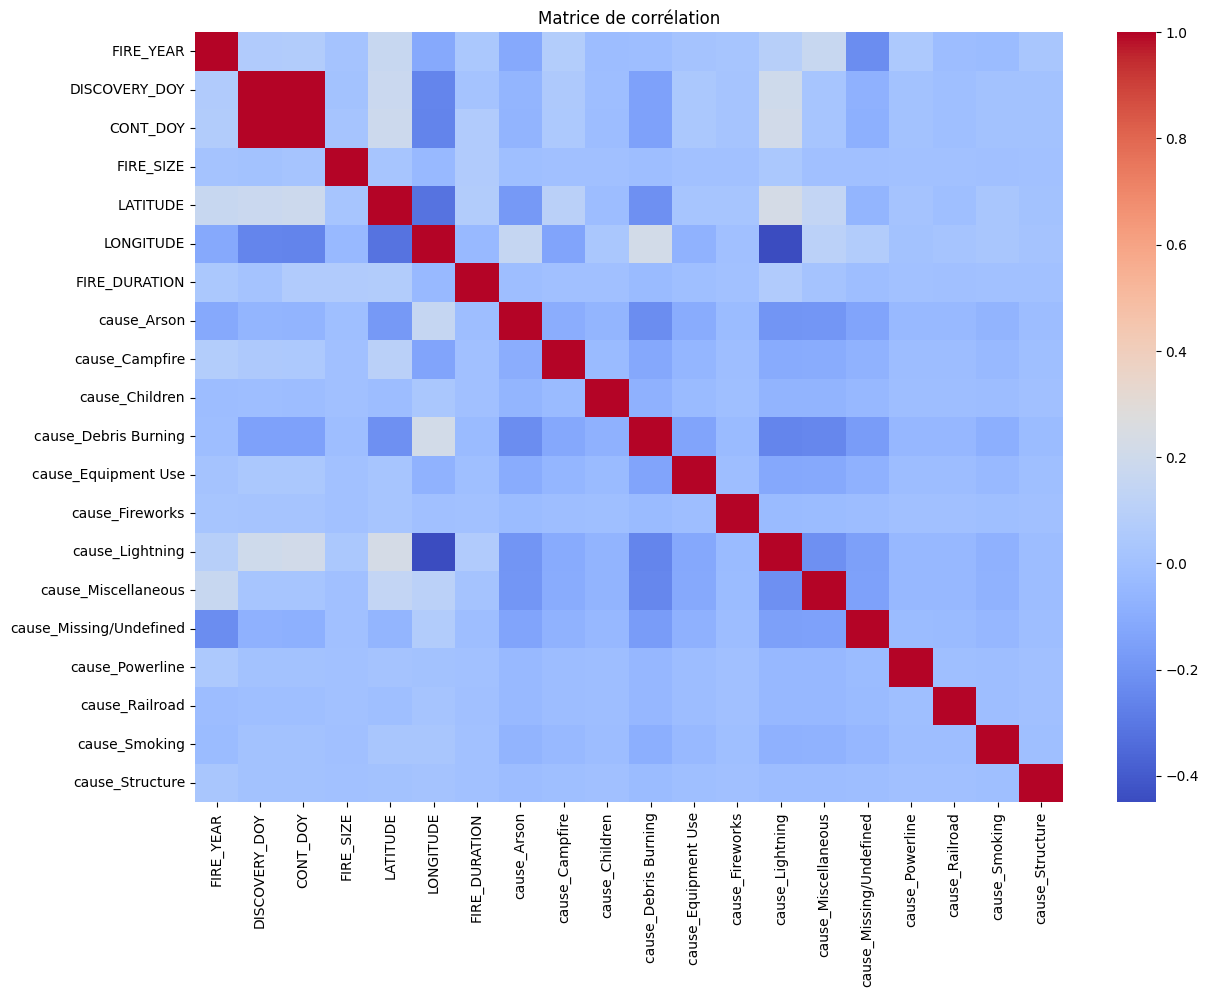

In [16]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Sélection des valeurs numériques
numeric_cols = ['FIRE_YEAR', 'DISCOVERY_DOY', 'CONT_DOY', 'FIRE_SIZE', 'LATITUDE', 'LONGITUDE']
df_numeric = df_clean[numeric_cols].copy()

# 2. One-hot encoding sur les causes
causes_ohe = pd.get_dummies(df_clean['STAT_CAUSE_DESCR'], prefix='cause')

# 3. Ajout de la nouvelle feature
df_numeric['FIRE_DURATION'] = df_clean['CONT_DATE'] - df_clean['DISCOVERY_DATE']

# 4. Assemblage et Matrice de corrélation
df_final = pd.concat([df_numeric, causes_ohe], axis=1)
corr_matrix = df_final.corr()

plt.figure(figsize=(14, 10))
sns.heatmap(corr_matrix, cmap='coolwarm')
plt.title("Matrice de corrélation")
plt.show()

These results are interesting: as expected, `DISCOVERY_DATE` and `CONT_DATE` are highly correlated, but the new `FIRE_DURATION` feature appears mostly independent. We also notice an unexpected link between `cause_Lightning` and `LONGITUDE`.

To uncover more complex patterns, we can discretize `DISCOVERY_DOY` into four seasons. This should reveal seasonal dependencies for specific fire causes.

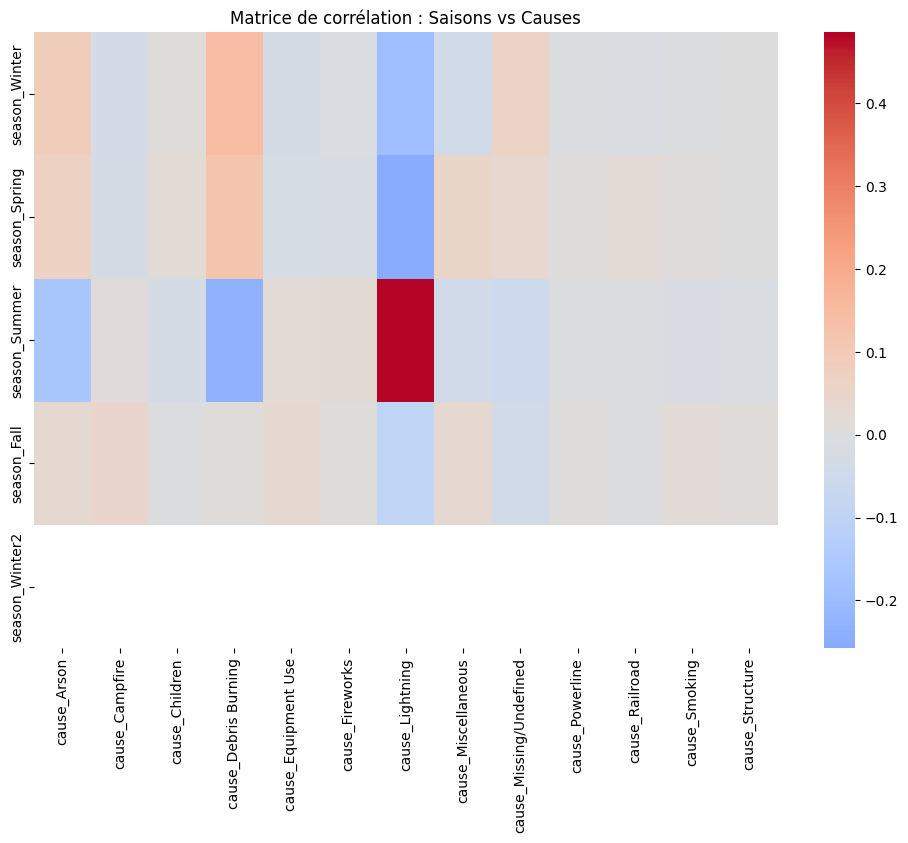

In [17]:
# 1. Découpage en saisons (bins basés sur les jours de l'année)
bins = [0, 60, 152, 244, 335, 366]
labels = ['Winter', 'Spring', 'Summer', 'Fall', 'Winter2']

df_clean['SEASON'] = pd.cut(df_clean['DISCOVERY_DOY'], bins=bins, labels=labels, ordered=False)
df_clean['SEASON'] = df_clean['SEASON'].replace('Winter2', 'Winter') # Fusionner la fin et le début d'année

# 2. One-hot encoding des saisons
seasons_ohe = pd.get_dummies(df_clean['SEASON'], prefix='season')

# 3. Assemblage avec les causes existantes et calcul de la corrélation
df_seasons_causes = pd.concat([seasons_ohe, causes_ohe], axis=1)
corr_seasons = df_seasons_causes.corr()

# 4. Affichage (on filtre pour ne voir que l'intersection Saisons / Causes)
plt.figure(figsize=(12, 8))
sns.heatmap(corr_seasons.loc[seasons_ohe.columns, causes_ohe.columns], cmap='coolwarm', center=0, annot=False)
plt.title("Matrice de corrélation : Saisons vs Causes")
plt.show()

The heatmap clearly shows how seasons impact fire causes

* **Summer**: Strongly correlated with lightning (the dark red square). On the flip side, human-driven causes like arson or debris burning are at their lowest[cite: 1].
* **Spring and Winter**: The trend reverses. Lightning is rare, but arson and debris fires are much more frequent.

